# Sliding-window likelihood-ratio test against the reference

Do the intervals between blinks in a recording still look like your **saved reference**, the first
10 minutes of one session? It's the same comparison the app makes live (Statistics › Current
session). All the logic is in `ocusense/core/baseline_drift.py` and the reference file in
`ocusense/reference.py`. Blinks and intervals come from the app's own `replay()`. Recordings and the
reference are only read, never changed. To make a reference from a recording, use
`analysis/set_reference.py`.

In [5]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ocusense").is_dir())
sys.path.insert(0, str(ROOT))

from ocusense import reference as reference_file
from ocusense.core import baseline_drift as bd
from ocusense.core.replay import replay
from ocusense.recording import default_directory
from ocusense.recording_files import RecordingError, group, read_file

FOLDER = default_directory()
RECORDING = None  # start time "YYYY-MM-DD HH:MM:SS" of the recording to analyse; None = the latest one
WINDOW_SECONDS = bd.WINDOW_SECONDS  # 300
STEP = 30.0
MIN_INTERVALS = 15
ALPHA = 0.01

## 1. The reference

Loaded from the file the app uses. Its intervals are kept as (onset_a, onset_b) pairs in seconds
since the reference session started, so they can be refitted and split here. The fit is the
maximum-likelihood log-normal: mu = mean of ln(interval), sigma with **ddof = 0**.

Reference: session of 10 Oct 2026, 21:26 (ear_2026-10-10_21-26-24.csv, ear_2026-10-10_21-36-24.csv)
n = 158, mu = 1.0113, sigma = 0.8175, median exp(mu) = 2.75 s
Calibration: 2026-10-10T21:26:24, closes below 0.35, reopens above 0.65


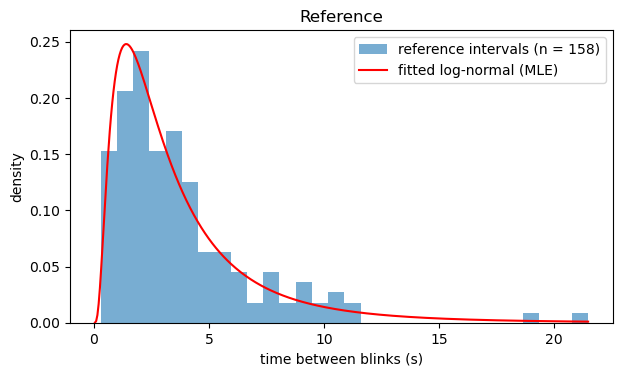

In [6]:
ref = reference_file.load()
if ref is None:
    raise SystemExit("No saved reference yet: run analysis/set_reference.py, or let the app save one.")
ref_intervals = np.array(ref.intervals)
print(f"Reference: session of {ref.label()} ({ref.source})")
print(f"n = {ref.n}, mu = {ref.mu:.4f}, sigma = {ref.sigma:.4f}, median exp(mu) = {ref.median:.2f} s")
if ref.calibration:
    print(f"Calibration: {ref.calibration.get('calibrated_at')}, closes below {ref.calibration.get('close_below')}, "
          f"reopens above {ref.calibration.get('reopen_above')}")

x = np.linspace(0.05, ref_intervals.max(), 400)
pdf = np.exp(-(np.log(x) - ref.mu) ** 2 / (2 * ref.sigma ** 2)) / (x * ref.sigma * math.sqrt(2 * math.pi))
plt.figure(figsize=(7, 3.8))
plt.hist(ref_intervals, bins=30, density=True, alpha=0.6, label=f"reference intervals (n = {ref.n})")
plt.plot(x, pdf, "r", label="fitted log-normal (MLE)")
plt.xlabel("time between blinks (s)"); plt.ylabel("density"); plt.legend(); plt.title("Reference")
plt.show()

Is the reference itself steady? The same fit on each half of the reference period, and the
same test between them. Halves that differ mean the reference mixes activities (e.g. reading
and skimming). That's fine if it reflects your usual mix.

In [7]:
halves = [bd.inside(ref.pairs, a, b) for a, b in [(0, ref.seconds / 2), (ref.seconds / 2, ref.seconds)]]
for (a, b), part in zip([(0, ref.seconds / 2), (ref.seconds / 2, ref.seconds)], halves):
    mu, sigma, n = bd.fit_lognormal(part)
    print(f"{a:3.0f}–{b:.0f} s: n = {n}, mu = {mu:.2f} (median {math.exp(mu):.2f} s), sigma = {sigma:.2f}")
test = bd.likelihood_ratio_test(*halves)
print(f"first vs second half: LR = {test.lr:.2f}, p = {test.p:.2g}")

  0–300 s: n = 56, mu = 1.35 (median 3.86 s), sigma = 0.84
300–600 s: n = 101, mu = 0.83 (median 2.29 s), sigma = 0.75
first vs second half: LR = 16.40, p = 0.00027


## 2. The recording to analyse

`RECORDING` picks it by start time. By default it's the latest recording that isn't the
reference itself (or the reference, if there's no other). It's replayed with its own saved
calibration.

In [8]:
files = []
for path in sorted(FOLDER.glob("ear_*.csv")):
    try:
        f = read_file(path)
    except RecordingError as error:
        print("excluded:", error)
        continue
    if f.calibration is not None:
        files.append(f)
recordings = group(files)

def started(r):
    return f"{r.started:%Y-%m-%d %H:%M:%S}"

is_reference = lambda r: r.started.isoformat(timespec="seconds") == ref.started_at
if RECORDING:
    recording = next(r for r in recordings if started(r) == RECORDING)
else:
    recording = ([r for r in recordings if not is_reference(r)] or recordings)[-1]
result = replay(recording.rows, recording.calibration)
pairs = result.distributions.intervals
END = result.timeline.times[-1]
same = is_reference(recording)

print("Recording:", recording.label(), "(the reference itself)" if same else "")
print("Calibration:", recording.calibration.label())
print(f"Valid frames {result.valid_frames / result.frames:.0%}, blinks {result.distributions.blinks}, "
      f"intervals {len(pairs)}")

Recording: Sat 10 Oct 2026, 20:00:05 · 85 min 48 s · 9 files 
Calibration: calibrated 2026-10-10 18:11:32 · closes below 35%, reopens above 65% · ear-personal-v2
Valid frames 59%, blinks 848, intervals 628


## 3. Sliding windows

300 s windows every 30 s from the start of the recording. Only full windows are evaluated. Each
window with at least 15 intervals is tested against the reference: LR on 2 degrees of freedom,
flagged when p < 0.01. If the recording is the reference itself, its first 10 minutes overlap
the reference and are marked so.

In [9]:
windows = bd.sliding_windows(pairs, 0.0, END, length=WINDOW_SECONDS, step=STEP, min_intervals=MIN_INTERVALS,
                             alpha=ALPHA, baseline=ref.intervals, baseline_seconds=ref.seconds if same else 0.0)
tested = [w for w in windows if w.p is not None]
skipped = [w for w in windows if w.p is None]
flagged = [w for w in windows if w.different]
print(f"windows: {len(windows)}, tested: {len(tested)}, not tested: {len(skipped)}"
      + (f" ({', '.join(sorted({w.status for w in skipped}))})" if skipped else ""))
print(f"flagged: {len(flagged)}" + (f", of which overlapping the reference: "
                                     f"{sum(w.overlaps_baseline for w in flagged)}" if same else ""))

windows: 162, tested: 127, not tested: 35 (not enough data)
flagged: 50


## 4. Timeline

p-value per window, log scale, plotted at the window's centre. Red points are flagged windows,
grey ticks at the bottom are windows with too few intervals, and the line breaks where windows
weren't tested.

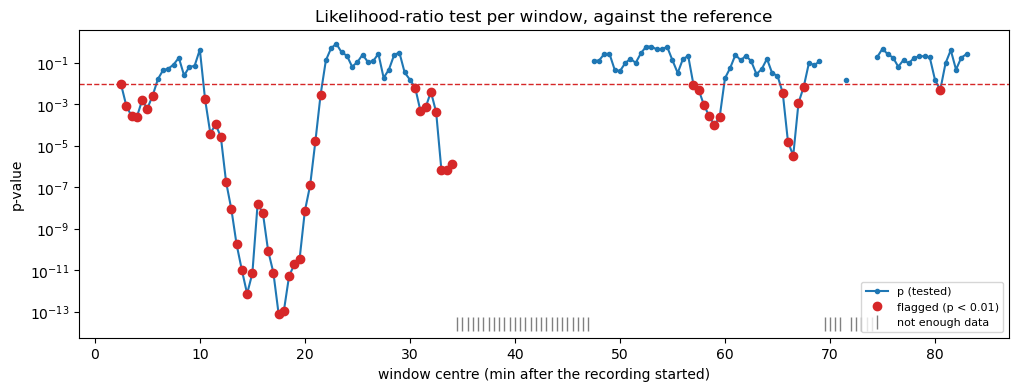

In [10]:
def centre(w):
    return (w.start + w.end) / 2 / 60

fig, ax = plt.subplots(figsize=(12, 4))
if same:
    ax.axvspan(0, ref.seconds / 60, color="tab:green", alpha=0.12, label="reference period")
ax.plot([centre(w) for w in windows], [w.p if w.p is not None else np.nan for w in windows], "-o", ms=3,
        color="tab:blue", label="p (tested)")
ax.plot([centre(w) for w in flagged], [w.p for w in flagged], "o", ms=6, color="tab:red",
        label=f"flagged (p < {ALPHA})")
floor = min([w.p for w in tested] + [ALPHA]) / 3
ax.plot([centre(w) for w in skipped], [floor] * len(skipped), "|", ms=10, color="grey", label="not enough data")
ax.axhline(ALPHA, color="tab:red", ls="--", lw=1)
ax.set_yscale("log")
ax.set(xlabel="window centre (min after the recording started)", ylabel="p-value",
       title="Likelihood-ratio test per window, against the reference")
ax.legend(loc="lower right", fontsize=8)
plt.show()

## 5. Window fit against the reference

mu_w (exp(mu_w) is the window's median interval) and sigma_w (spread) per tested window, with
the reference values as dashed lines.

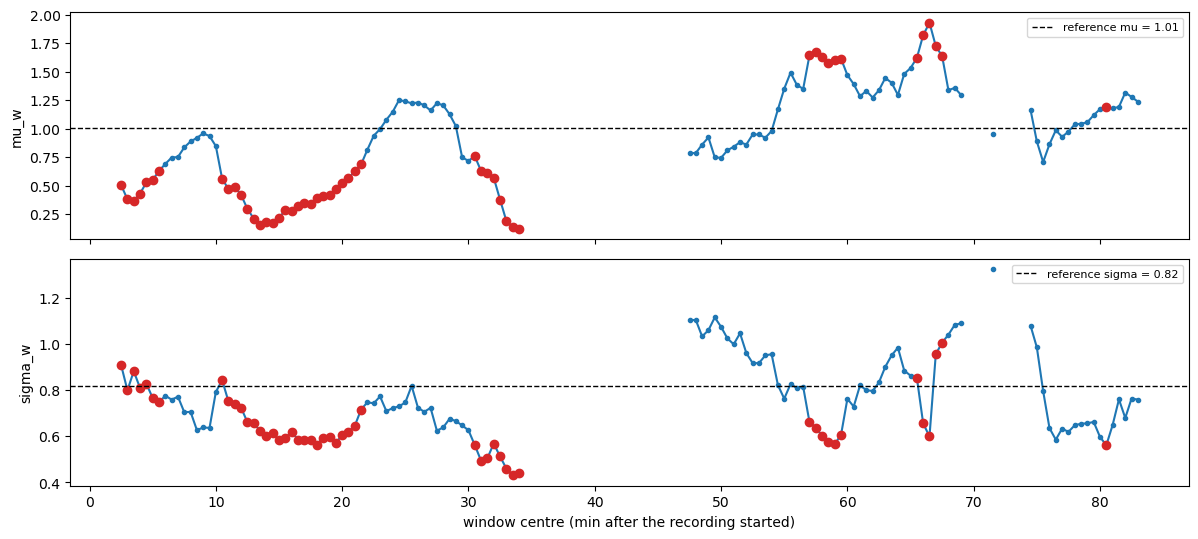

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
for ax, attr, base, label in ((axes[0], "mu", ref.mu, "mu_w"), (axes[1], "sigma", ref.sigma, "sigma_w")):
    if same:
        ax.axvspan(0, ref.seconds / 60, color="tab:green", alpha=0.12)
    ax.plot([centre(w) for w in windows], [getattr(w.fit, attr) if w.p is not None else np.nan for w in windows],
            "-o", ms=3)  # NaN: the line breaks where windows weren't tested
    ax.plot([centre(w) for w in flagged], [getattr(w.fit, attr) for w in flagged], "o", ms=6, color="tab:red")
    ax.axhline(base, color="k", ls="--", lw=1, label=f"reference {attr} = {base:.2f}")
    ax.set_ylabel(label); ax.legend(loc="upper right", fontsize=8)
axes[1].set_xlabel("window centre (min after the recording started)")
plt.tight_layout(); plt.show()

## 6. Flagged windows

In [12]:
print(f"{'window (min)':>14} {'n':>4} {'mu_w':>6} {'sigma_w':>8} {'median s':>9} {'LR':>7} {'p':>9}  note")
for w in flagged:
    print(f"{w.start / 60:6.1f}–{w.end / 60:5.1f}  {w.n:4d} {w.fit.mu:6.2f} {w.fit.sigma:8.2f} "
          f"{math.exp(w.fit.mu):9.2f} {w.lr:7.2f} {w.p:9.2g}  {'overlaps reference' if w.overlaps_baseline else ''}")

  window (min)    n   mu_w  sigma_w  median s      LR         p  note
   0.0–  5.0    29   0.51     0.91      1.66    9.37    0.0093  
   0.5–  5.5    29   0.38     0.80      1.46   14.11   0.00086  
   1.0–  6.0    34   0.37     0.88      1.45   16.40   0.00027  
   1.5–  6.5    44   0.43     0.81      1.54   16.63   0.00025  
   2.0–  7.0    51   0.53     0.83      1.70   12.90    0.0016  
   2.5–  7.5    63   0.55     0.77      1.73   14.72   0.00064  
   3.0–  8.0    73   0.63     0.75      1.88   11.90    0.0026  
   8.0– 13.0    60   0.56     0.84      1.75   12.69    0.0018  
   8.5– 13.5    63   0.47     0.75      1.60   20.27     4e-05  
   9.0– 14.0    58   0.49     0.74      1.63   18.23   0.00011  
   9.5– 14.5    50   0.42     0.72      1.52   21.04   2.7e-05  
  10.0– 15.0    47   0.30     0.66      1.35   31.06   1.8e-07  
  10.5– 15.5    46   0.21     0.66      1.24   37.07   8.9e-09  
  11.0– 16.0    48   0.16     0.62      1.17   44.91   1.8e-10  
  11.5– 16.5    56  

## 7. All recordings against the reference

A one-line summary per recording. Recordings made with a different calibration are compared
too, because the reference is kept across recalibrations, but their detection thresholds may differ.

In [13]:
for r in recordings:
    rr = replay(r.rows, r.calibration)
    own = is_reference(r)
    ws = bd.sliding_windows(rr.distributions.intervals, 0.0, rr.timeline.times[-1], length=WINDOW_SECONDS,
                            step=STEP, min_intervals=MIN_INTERVALS, alpha=ALPHA, baseline=ref.intervals,
                            baseline_seconds=ref.seconds if own else 0.0)
    print(f"{r.label()}{' (reference)' if own else ''}: valid {rr.valid_frames / rr.frames:.0%}, "
          f"windows {len(ws)}, tested {sum(w.p is not None for w in ws)}, flagged {sum(w.different for w in ws)}")

Sat 10 Oct 2026, 18:11:32 · 60 min 1 s · 7 files: valid 57%, windows 111, tested 68, flagged 31
Sat 10 Oct 2026, 20:00:05 · 85 min 48 s · 9 files: valid 59%, windows 162, tested 127, flagged 50
Sat 10 Oct 2026, 21:26:24 · 10 min 37 s · 2 files (reference): valid 100%, windows 12, tested 12, flagged 1


## Limitations

- **Many, overlapping tests.** Consecutive windows share 90% of their data (300 s windows, 30 s
  step), so neighbouring p-values aren't independent and flags come in runs. About 100 windows are
  tested per hour with no multiple-testing correction, so even with no real change expect some
  false flags at ALPHA = 0.01. Treat a single flagged window as weak evidence, and a sustained run
  well below the line as stronger evidence.
- **Small samples.** A window has roughly 15–100 intervals. The fitted mu_w and especially
  sigma_w are noisy, and the chi-square approximation to the LR distribution is only
  asymptotic. With these sample sizes the p-values are approximate.
- **The reference is one particular 10 minutes.** "Different" means "not distributed like those
  10 minutes": a different activity (long reading, talking) counts as different just as
  drift does. Comparisons mean most during the same kind of activity as the reference.
- **Tracking gaps shape the data.** Intervals are only measured inside valid segments, so long
  intervals are more likely to be lost to a gap. A window with poor tracking can look "faster"
  than it is, and windows with too few intervals aren't tested at all.
- **Calibration.** The reference is kept across recalibrations. Different thresholds can change
  which closures count as blinks, so compare sessions with similar calibrations where possible.
- **The model.** A log-normal is assumed for both reference and windows. The test asks whether one
  log-normal explains both, not whether log-normal is the right shape. It says nothing about why
  the intervals changed (fatigue, task, lighting, detection).